# Лабораторная работа №3: Foundation models для сегментации: SAM/SAM 2

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Получить маски по point и box prompts.
- Автоматически сформировать prompts из GT или детектора.
- Сравнить zero-shot и refinement head.


## Теоретическая часть

Promptable segmentation оценивает маску $M=f(I,p)$ по изображению и prompt $p$ (точка, box или маска). SAM разделяет тяжёлый image encoder и лёгкий prompt/mask decoder, поэтому один embedding изображения можно использовать для многих запросов.

![SAM architecture](https://raw.githubusercontent.com/facebookresearch/segment-anything/main/assets/model_diagram.png)


### Математическая постановка

Качество promptable-модели оценивают не только IoU, но и числом взаимодействий до достижения целевого качества: $N@IoU\geq\tau$. Для ускорения разметки важна доля масок, принимаемых без существенной коррекции.


### Материалы

- [Segment Anything](https://github.com/facebookresearch/segment-anything)
- [Transformers SAM docs](https://huggingface.co/docs/transformers/model_doc/sam)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Получить маски по point и box prompts.
2. Автоматически сформировать prompts из GT или детектора.
3. Сравнить zero-shot и refinement head.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** SAM ViT-B/MobileSAM inference, frozen encoder.
- **Ограничение данных:** до 200 изображений 512 px.
- **Fallback:** CPU на 20 изображениях или MobileSAM.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [1]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np

SEED = 67
FAST_DEV_RUN = False  # True — только проверка связности на уменьшенной выборке; не отчётный результат
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch = None
    DEVICE = "cpu"
DATA_ROOT = Path.cwd() / "data"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT)})


{'device': 'cpu', 'fast_dev_run': False, 'data_root': 'c:\\Anton\\16 триместр\\SOTA\\lab3\\data'}


In [2]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

In [3]:
# Библиотеки
from pathlib import Path
import json
import numpy as np
import torch

from datasets import load_dataset
from transformers import SamModel, SamProcessor

import matplotlib.pyplot as plt

from tqdm.auto import tqdm

import torch.nn.functional as F
from torchvision.transforms.functional import to_tensor
from torchvision.models.segmentation import lraspp_mobilenet_v3_large
import torch.nn as nn

from scipy.ndimage import distance_transform_edt
from torch.utils.data import Subset

c:\Anton\16 триместр\movenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Загрузка SAM и отложенных масок

*Вес: 1 балл.*

**Постановка.** Сравнение prompts возможно лишь на одних размеченных изображениях.

Выполните следующие действия:
1. Загрузите pretrained SAM и test Oxford-IIIT Pet.
2. Зафиксируйте индексы проверки.

**Результат.** dataset_manifest.json и объекты processor, model, eval_ds.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [4]:
# ------------------------------------------------------------
# 1. Загружаем pretrained SAM
# ------------------------------------------------------------

from transformers import SamProcessor, SamModel
from torchvision.datasets import OxfordIIITPet
from torch.utils.data import Subset

MODEL_ID = "facebook/sam-vit-base"

processor = SamProcessor.from_pretrained(MODEL_ID)
model = SamModel.from_pretrained(MODEL_ID)

model = model.to(DEVICE)
model.eval()


# ------------------------------------------------------------
# 2. Загружаем Oxford-IIIT Pet через torchvision
# ------------------------------------------------------------

test_ds = OxfordIIITPet(
    root=DATA_ROOT,
    split="test",
    target_types="segmentation",
    download=True,
)


# ------------------------------------------------------------
# 3. Фиксируем индексы проверки
# ------------------------------------------------------------

rng = np.random.default_rng(SEED)

if FAST_DEV_RUN:
    n_eval = min(20, len(test_ds))
else:
    n_eval = min(200, len(test_ds))

eval_indices = rng.choice(
    len(test_ds),
    size=n_eval,
    replace=False,
)

eval_indices = sorted(eval_indices.tolist())

# Фиксированный subset по выбранным индексам
eval_ds = Subset(test_ds, eval_indices)


# ------------------------------------------------------------
# 4. Сохраняем manifest
# ------------------------------------------------------------

manifest = {
    "dataset": "Oxford-IIIT Pet",
    "split": "test",
    "model": MODEL_ID,
    "seed": SEED,
    "fast_dev_run": FAST_DEV_RUN,
    "num_samples": len(eval_ds),
    "indices": eval_indices,
    "data_root": str(DATA_ROOT),
}

manifest_path = ARTIFACTS / "dataset_manifest.json"

with open(manifest_path, "w", encoding="utf-8") as f:
    json.dump(manifest, f, ensure_ascii=False, indent=2)


# ------------------------------------------------------------
# 5. Минимальные проверки
# ------------------------------------------------------------

check(
    len(eval_ds) == n_eval,
    f"Зафиксирован evaluation subset: {len(eval_ds)} изображений",
)

check(
    manifest_path.exists(),
    f"Создан {manifest_path}",
)

check(
    model is not None and processor is not None,
    "SAM model и processor загружены",
)

check(
    len(eval_indices) == len(set(eval_indices)),
    "Индексы evaluation subset уникальны",
)

print({
    "model": MODEL_ID,
    "device": DEVICE,
    "eval_samples": len(eval_ds),
    "manifest": str(manifest_path),
    "data_root": str(DATA_ROOT),
})

Loading weights: 100%|██████████| 314/314 [00:00<00:00, 746.92it/s]

✔ Зафиксирован evaluation subset: 200 изображений
✔ Создан artifacts\dataset_manifest.json
✔ SAM model и processor загружены
✔ Индексы evaluation subset уникальны
{'model': 'facebook/sam-vit-base', 'device': 'cpu', 'eval_samples': 200, 'manifest': 'artifacts\\dataset_manifest.json', 'data_root': 'c:\\Anton\\16 триместр\\SOTA\\lab3\\data'}


### Геометрия подсказок и IoU

*Вес: 1 балл.*

**Постановка.** Box и point должны воспроизводимо извлекаться из одной истинной маски.

Выполните следующие действия:
1. Реализуйте IoU масок и ограничивающий прямоугольник.
2. Документируйте, что подсказки из GT моделируют действия разметчика.

**Результат.** Функции iou и box_from_mask.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [5]:
# ------------------------------------------------------------
# Геометрия подсказок и IoU
# ------------------------------------------------------------
def iou(mask_a, mask_b):
    mask_a = np.asarray(mask_a, dtype=bool)
    mask_b = np.asarray(mask_b, dtype=bool)

    intersection = np.logical_and(mask_a, mask_b).sum()
    union = np.logical_or(mask_a, mask_b).sum()

    # Если обе маски пустые, считаем их полностью совпадающими.
    if union == 0:
        return 1.0

    return float(intersection / union)

def box_from_mask(mask):
    mask = np.asarray(mask, dtype=bool)

    ys, xs = np.where(mask)

    x_min = int(xs.min())
    y_min = int(ys.min())
    x_max = int(xs.max())
    y_max = int(ys.max())

    return [x_min, y_min, x_max, y_max]

# ------------------------------------------------------------
# Минимальные проверки
# ------------------------------------------------------------
test_mask = np.zeros((10, 10), dtype=bool)
test_mask[2:6, 3:7] = True

test_box = box_from_mask(test_mask)

check(
    test_box == [3, 2, 6, 5],
    f"Bounding box построен корректно: {test_box}",
)

check(
    np.isclose(iou(test_mask, test_mask), 1.0),
    "IoU маски с самой собой равен 1",
)

check(
    np.isclose(iou(test_mask, np.zeros_like(test_mask)), 0.0),
    "IoU непересекающихся масок равен 0",
)

print({
    "test_box": test_box,
    "test_iou_self": iou(test_mask, test_mask),
})

✔ Bounding box построен корректно: [3, 2, 6, 5]
✔ IoU маски с самой собой равен 1
✔ IoU непересекающихся масок равен 0
{'test_box': [3, 2, 6, 5], 'test_iou_self': 1.0}


### Предсказание SAM по подсказке

*Вес: 1 балл.*

**Постановка.** Encoder и mask decoder должны получать корректный тип prompt.

Выполните следующие действия:
1. Подайте point или box в processor.
2. Выберите маску по предсказанной SAM оценке IoU.

**Результат.** Функция predict_sam с бинарной маской исходного размера.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [6]:
# ------------------------------------------------------------
# Предсказание SAM по point / box prompt
# ------------------------------------------------------------
def predict_sam(image, point=None, box=None):
    """
    Запускает SAM по одной подсказке: point ИЛИ box.
    Возвращает бинарную маску в размере исходного изображения.
    """
    if (point is None) == (box is None):
        raise ValueError("Нужно передать ровно одну подсказку: point ИЛИ box")

    width, height = image.size

    if point is not None:
        point = [float(point[0]), float(point[1])]
        inputs = processor(
            images=image,
            input_points=[[point]],
            input_labels=[[1]],
            return_tensors="pt",
        )
    else:
        box = [float(v) for v in box]
        inputs = processor(
            images=image,
            input_boxes=[[box]],
            return_tensors="pt",
        )

    inputs = {
        key: value.to(DEVICE) if torch.is_tensor(value) else value
        for key, value in inputs.items()
    }

    with torch.no_grad():
        outputs = model(**inputs)

    # Возвращаем маски к исходному размеру с учётом преобразований processor.
    postprocessed_masks = processor.image_processor.post_process_masks(
        outputs.pred_masks.detach().cpu(),
        inputs.get("original_sizes", torch.tensor([[height, width]])),
        inputs.get("reshaped_input_sizes", torch.tensor([[height, width]])),
    )

    # Выбираем маску с наибольшим предсказанным IoU.
    best_idx = outputs.iou_scores.reshape(-1).argmax().item()

    masks = postprocessed_masks[0]
    masks = masks.reshape(-1, masks.shape[-2], masks.shape[-1])

    best_mask = masks[best_idx].numpy()

    # В зависимости от версии Transformers post_process_masks
    # может вернуть логиты или уже бинарные маски.
    if best_mask.dtype == np.bool_:
        return best_mask

    return best_mask > 0


# ------------------------------------------------------------
# Минимальная проверка функции на одном объекте eval_ds
# ------------------------------------------------------------

image, gt_mask_raw = eval_ds[1]

# В исходной GT-маске Oxford-IIIT Pet:
#   1 — foreground / объект
#   2 — background / фон
#   3 — boundary / граница
#
# Для сравнения с SAM нам нужна бинарная маска объекта.
gt_mask_raw = np.asarray(gt_mask_raw)
gt_mask = gt_mask_raw == 1


# ------------------------------------------------------------
# Строим воспроизводимую point prompt внутри объекта
# ------------------------------------------------------------

ys, xs = np.where(gt_mask)

if len(xs) == 0:
    raise ValueError(
        "В тестовой GT-маске не найден объект класса 1"
    )

test_point = [
    int(xs[len(xs) // 2]),
    int(ys[len(ys) // 2]),
]


# ------------------------------------------------------------
# Получаем предсказание SAM
# ------------------------------------------------------------

pred_mask = predict_sam(
    image=image,
    point=test_point,
)


# ------------------------------------------------------------
# Минимальные проверки результата
# ------------------------------------------------------------

if pred_mask.shape != gt_mask.shape:
    raise ValueError(
        f"Размеры масок не совпадают: "
        f"{pred_mask.shape} != {gt_mask.shape}"
    )

if pred_mask.dtype != np.bool_:
    raise ValueError(
        f"Предсказанная маска должна иметь dtype bool, "
        f"получено: {pred_mask.dtype}"
    )


# ------------------------------------------------------------
# Сохраняем артефакт smoke-test
# ------------------------------------------------------------

sam_test_artifact = {
    "dataset": "Oxford-IIIT Pet",
    "split": "test",
    "model": MODEL_ID,
    "index": int(eval_indices[1]),
    "prompt_type": "point",
    "prompt": test_point,
    "gt_classes": [1, 2, 3],
    "gt_foreground_class": 1,
    "image_size": list(image.size),
    "pred_mask_shape": list(pred_mask.shape),
    "pred_mask_area": int(pred_mask.sum()),
    "gt_area": int(gt_mask.sum()),
    "iou_with_gt": float(iou(pred_mask, gt_mask)),
}

sam_test_path = ARTIFACTS / "sam_prediction_test.json"

with open(sam_test_path, "w", encoding="utf-8") as f:
    json.dump(
        sam_test_artifact,
        f,
        ensure_ascii=False,
        indent=2,
    )

print(f"Артефакт сохранён: {sam_test_path}")

Артефакт сохранён: artifacts\sam_prediction_test.json


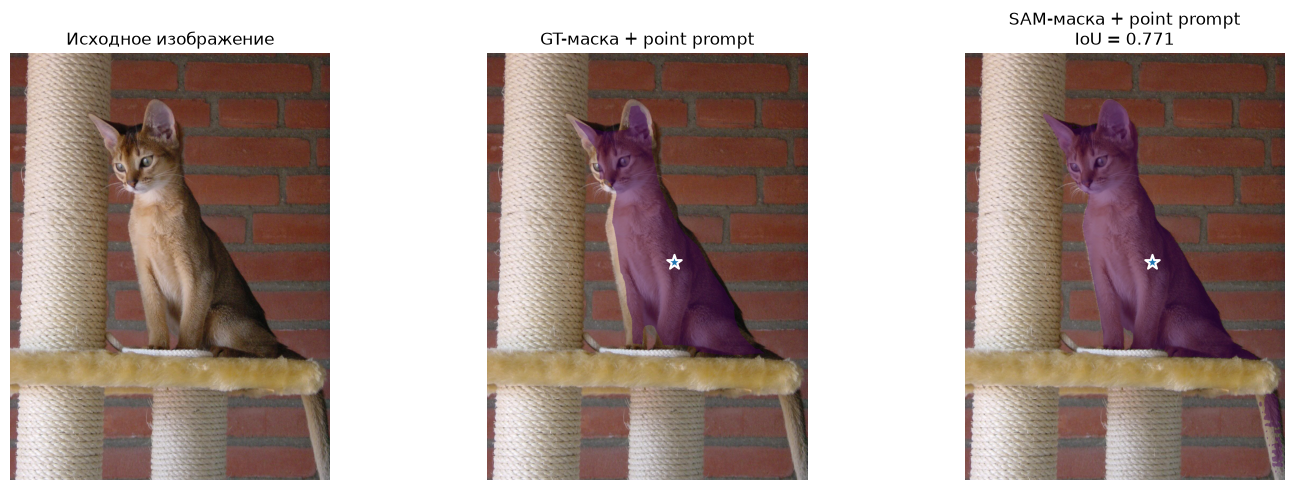

In [7]:
# ------------------------------------------------------------
# Визуализация: исходное изображение → GT → SAM
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# 1. Исходное изображение
axes[0].imshow(image)
axes[0].set_title("Исходное изображение")
axes[0].axis("off")


# 2. GT-маска + point prompt
axes[1].imshow(image)
axes[1].imshow(
    np.ma.masked_where(~gt_mask, gt_mask),
    alpha=0.45,
)
axes[1].scatter(
    test_point[0],
    test_point[1],
    s=120,
    marker="*",
    edgecolors="white",
    linewidths=1.5,
)
axes[1].set_title("GT-маска + point prompt")
axes[1].axis("off")


# 3. SAM-маска + point prompt
axes[2].imshow(image)
axes[2].imshow(
    np.ma.masked_where(~pred_mask, pred_mask),
    alpha=0.45,
)
axes[2].scatter(
    test_point[0],
    test_point[1],
    s=120,
    marker="*",
    edgecolors="white",
    linewidths=1.5,
)
axes[2].set_title(
    f"SAM-маска + point prompt\nIoU = {iou(pred_mask, gt_mask):.3f}"
)
axes[2].axis("off")

plt.tight_layout()
plt.show()

### Сравнение point и box

*Вес: 1 балл.*

**Постановка.** Степень интерактивной подсказки влияет на качество сегментации.

Выполните следующие действия:
1. Получите две маски для каждого отложенного изображения.
2. Сохраните IoU, площади и координаты prompts.

**Результат.** prompt_results.json с реальными оценками SAM.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [8]:
# Исключаем элемент с позицией 155 в eval_ds
remove_position = 155

if remove_position < len(eval_ds):
    removed_dataset_index = int(eval_indices[remove_position])

    eval_indices = [
        idx for pos, idx in enumerate(eval_indices)
        if pos != remove_position
    ]

    eval_ds = Subset(test_ds, eval_indices)

    print(f"Исключён eval_ds[{remove_position}]")
    print(f"Исходный индекс в test_ds: {removed_dataset_index}")
    print(f"Осталось изображений: {len(eval_ds)}")
else:
    print("Позиция 155 уже отсутствует в eval_ds")

Исключён eval_ds[155]
Исходный индекс в test_ds: 2856
Осталось изображений: 199


In [9]:
# ------------------------------------------------------------
# Сравнение point и box prompt на всех eval-изображениях
# ------------------------------------------------------------
prompt_results = []

for i in tqdm(range(len(eval_ds)), desc="Сравнение point и box"):
    # --------------------------------------------------------
    # 1. Загружаем изображение и готовим бинарную GT-маску
    # --------------------------------------------------------
    image, gt_mask_raw = eval_ds[i]

    gt_mask_raw = np.asarray(gt_mask_raw)

    # Oxford-IIIT Pet:
    # 1 — объект, 2 — фон, 3 — граница
    gt_mask = gt_mask_raw == 1

    ys, xs = np.where(gt_mask)

    if len(xs) == 0:
        print(f"Пропускаем eval_ds[{i}]: пустая GT-маска")
        continue

    height, width = gt_mask.shape

    # --------------------------------------------------------
    # 2. Формируем point prompt внутри объекта
    # --------------------------------------------------------

    # Детерминированная точка из пикселей объекта.
    # Выбор центрального элемента списка воспроизводим.
    point = [
        int(xs[len(xs) // 2]),
        int(ys[len(ys) // 2]),
    ]

    # --------------------------------------------------------
    # 3. Формируем box prompt из GT-маски
    # --------------------------------------------------------

    box = box_from_mask(gt_mask)

    # --------------------------------------------------------
    # 4. Получаем предсказания SAM
    # --------------------------------------------------------

    pred_point = predict_sam(
        image=image,
        point=point,
    )

    pred_box = predict_sam(
        image=image,
        box=box,
    )

    # --------------------------------------------------------
    # 5. Считаем реальные метрики относительно GT
    # --------------------------------------------------------

    point_iou = iou(pred_point, gt_mask)
    box_iou = iou(pred_box, gt_mask)

    point_area = int(pred_point.sum())
    box_area = int(pred_box.sum())
    gt_area = int(gt_mask.sum())

    # --------------------------------------------------------
    # 6. Сохраняем результат для изображения
    # --------------------------------------------------------

    prompt_results.append({
        "eval_position": int(i),
        "dataset_index": int(eval_indices[i]),
        "image_size": {
            "width": int(width),
            "height": int(height),
        },
        "gt_area": gt_area,
        "point": {
            "coordinates": point,
            "predicted_area": point_area,
            "iou": float(point_iou),
        },
        "box": {
            "coordinates_xyxy": box,
            "predicted_area": box_area,
            "iou": float(box_iou),
        },
    })


# ------------------------------------------------------------
# 7. Сохраняем обязательный артефакт prompt_results.json
# ------------------------------------------------------------

prompt_results_artifact = {
    "dataset": "Oxford-IIIT Pet",
    "split": "test",
    "model": MODEL_ID,
    "seed": SEED,
    "fast_dev_run": FAST_DEV_RUN,
    "num_images": len(prompt_results),
    "mask_definition": "GT foreground is class 1",
    "metrics": {
        "iou": "Intersection over Union between SAM mask and binary GT foreground mask",
        "area": "Number of foreground pixels in the binary mask",
    },
    "results": prompt_results,
}

prompt_results_path = ARTIFACTS / "prompt_results.json"

with open(prompt_results_path, "w", encoding="utf-8") as f:
    json.dump(
        prompt_results_artifact,
        f,
        ensure_ascii=False,
        indent=2,
    )


# ------------------------------------------------------------
# 8. Краткие проверки и сводка
# ------------------------------------------------------------

if len(prompt_results) > len(eval_ds):
    raise RuntimeError("Результатов больше, чем изображений в eval_ds")

skipped_count = len(eval_ds) - len(prompt_results)

print(f"Обработано изображений: {len(prompt_results)}")
print(f"Пропущено изображений: {skipped_count}")

if not prompt_results_path.exists():
    raise FileNotFoundError(f"Артефакт не создан: {prompt_results_path}")

point_ious = [row["point"]["iou"] for row in prompt_results]
box_ious = [row["box"]["iou"] for row in prompt_results]

summary = {
    "num_images": len(prompt_results),
    "mean_point_iou": float(np.mean(point_ious)),
    "mean_box_iou": float(np.mean(box_ious)),
    "mean_point_area": float(np.mean(
        [row["point"]["predicted_area"] for row in prompt_results]
    )),
    "mean_box_area": float(np.mean(
        [row["box"]["predicted_area"] for row in prompt_results]
    )),
    "artifact": str(prompt_results_path),
}

print(json.dumps(summary, ensure_ascii=False, indent=2))

Сравнение point и box: 100%|██████████| 199/199 [42:14<00:00, 12.74s/it]

Обработано изображений: 199
Пропущено изображений: 0
{
  "num_images": 199,
  "mean_point_iou": 0.6496695018997778,
  "mean_box_iou": 0.7781091932319515,
  "mean_point_area": 52510.34170854271,
  "mean_box_area": 61238.89949748744,
  "artifact": "artifacts\\prompt_results.json"
}


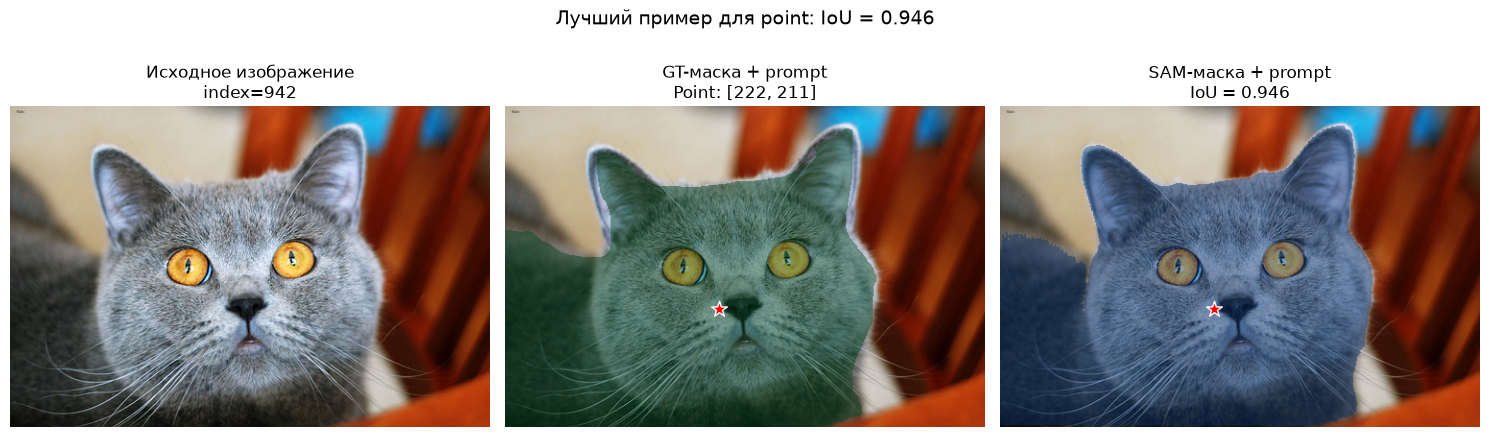

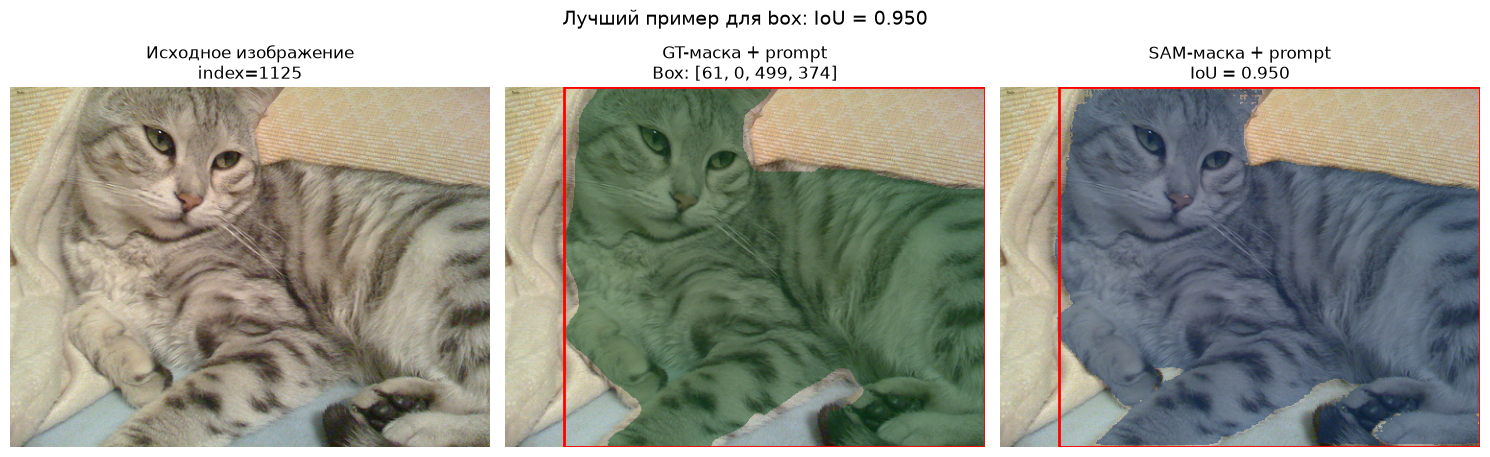

In [10]:
# ------------------------------------------------------------
# Визуализация лучших примеров для point и box по IoU
# ------------------------------------------------------------
def show_best_prompt_example(prompt_type):
    # Находим изображение с максимальным IoU для выбранного prompt.
    best_result = max(
        prompt_results,
        key=lambda row: row[prompt_type]["iou"],
    )

    # Восстанавливаем изображение и GT по исходному индексу датасета.
    dataset_index = best_result["dataset_index"]
    image, gt_mask_raw = test_ds[dataset_index]

    gt_mask = np.asarray(gt_mask_raw) == 1

    # Получаем prompt из сохранённых результатов.
    if prompt_type == "point":
        point = best_result["point"]["coordinates"]
        pred_mask = predict_sam(image=image, point=point)
        prompt_description = f"Point: {point}"

    elif prompt_type == "box":
        box = best_result["box"]["coordinates_xyxy"]
        pred_mask = predict_sam(image=image, box=box)
        prompt_description = f"Box: {box}"

    else:
        raise ValueError("prompt_type должен быть 'point' или 'box'")
    # --------------------------------------------------------
    # Рисуем три панели
    # --------------------------------------------------------
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # 1. Исходное изображение
    axes[0].imshow(image)
    axes[0].set_title(
        f"Исходное изображение\nindex={dataset_index}"
    )
    axes[0].axis("off")

    # 2. GT-маска + prompt
    axes[1].imshow(image)
    axes[1].imshow(
        np.ma.masked_where(~gt_mask, gt_mask),
        alpha=0.45,
        cmap="Greens",
        vmin=0,
        vmax=1,
    )

    if prompt_type == "point":
        axes[1].scatter(
            point[0], point[1],
            s=140, marker="*",
            color="red", edgecolors="white",
        )
    else:
        x1, y1, x2, y2 = box
        axes[1].add_patch(
            plt.Rectangle(
                (x1, y1), x2 - x1, y2 - y1,
                fill=False, edgecolor="red", linewidth=2,
            )
        )

    axes[1].set_title(f"GT-маска + prompt\n{prompt_description}")
    axes[1].axis("off")

    # 3. Маска SAM + тот же prompt
    axes[2].imshow(image)
    axes[2].imshow(
        np.ma.masked_where(~pred_mask, pred_mask),
        alpha=0.45,
        cmap="Blues",
        vmin=0,
        vmax=1,
    )

    if prompt_type == "point":
        axes[2].scatter(
            point[0], point[1],
            s=140, marker="*",
            color="red", edgecolors="white",
        )
    else:
        x1, y1, x2, y2 = box
        axes[2].add_patch(
            plt.Rectangle(
                (x1, y1), x2 - x1, y2 - y1,
                fill=False, edgecolor="red", linewidth=2,
            )
        )

    actual_iou = iou(pred_mask, gt_mask)

    axes[2].set_title(
        f"SAM-маска + prompt\nIoU = {actual_iou:.3f}"
    )
    axes[2].axis("off")

    plt.suptitle(
        f"Лучший пример для {prompt_type}: "
        f"IoU = {actual_iou:.3f}",
        fontsize=14,
    )
    plt.tight_layout()
    plt.show()
# ------------------------------------------------------------
# Показываем лучший пример для каждого типа prompt
# ------------------------------------------------------------
show_best_prompt_example("point")
show_best_prompt_example("box")

### Обучение supervised baseline

*Вес: 1 балл.*

**Постановка.** Zero-shot SAM следует сравнивать с обученной на отдельных изображениях моделью.

Выполните следующие действия:
1. Подготовьте бинарные маски trainval.
2. Обучите LRASPP без доступа к test и сохраните веса.

**Результат.** supervised.pt с обученными весами.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [11]:
# ------------------------------------------------------------
# 1. Путь к файлу весов
# ------------------------------------------------------------

supervised_path = ARTIFACTS / "supervised.pt"

if not supervised_path.exists():
    raise FileNotFoundError(
        f"Файл с весами не найден: {supervised_path}"
    )


# ------------------------------------------------------------
# 2. Загружаем checkpoint
# ------------------------------------------------------------

checkpoint = torch.load(
    supervised_path,
    map_location="cpu",
    weights_only=True,
)

# Поддерживаем checkpoint со словарём model_state_dict
# и обычный state_dict.
if (
    isinstance(checkpoint, dict)
    and "model_state_dict" in checkpoint
):
    state_dict = checkpoint["model_state_dict"]
else:
    state_dict = checkpoint

if not isinstance(state_dict, dict):
    raise TypeError(
        "Файл не содержит словарь параметров модели."
    )


# ------------------------------------------------------------
# 3. Создаём архитектуру LRASPP на три класса
# ------------------------------------------------------------

NUM_CLASSES = 3

model_supervised = lraspp_mobilenet_v3_large(
    weights=None,
    weights_backbone=None,
    num_classes=NUM_CLASSES,
)


# ------------------------------------------------------------
# 4. Проверяем совместимость весов
# ------------------------------------------------------------

model_state = model_supervised.state_dict()

missing_keys = sorted(set(model_state) - set(state_dict))
unexpected_keys = sorted(set(state_dict) - set(model_state))

shape_mismatches = [
    key
    for key in set(model_state) & set(state_dict)
    if model_state[key].shape != state_dict[key].shape
]

if missing_keys or unexpected_keys or shape_mismatches:
    details = []

    if missing_keys:
        details.append(f"Отсутствуют ключи: {missing_keys}")

    if unexpected_keys:
        details.append(f"Лишние ключи: {unexpected_keys}")

    if shape_mismatches:
        details.append(
            "Несовпадающие размеры: "
            + str({
                key: {
                    "ожидается": tuple(model_state[key].shape),
                    "в файле": tuple(state_dict[key].shape),
                }
                for key in shape_mismatches
            })
        )

    raise RuntimeError(
        "Checkpoint несовместим с LRASPP на три класса.\n"
        + "\n".join(details)
    )


# ------------------------------------------------------------
# 5. Загружаем веса и переводим модель в режим инференса
# ------------------------------------------------------------

model_supervised.load_state_dict(state_dict, strict=True)

model_supervised = model_supervised.to(DEVICE)
model_supervised.eval()


# ------------------------------------------------------------
# 6. Сохраняем информацию о загрузке
# ------------------------------------------------------------

supervised_load_info = {
    "weights_path": str(supervised_path),
    "architecture": "LRASPP-MobileNetV3-Large",
    "num_classes": NUM_CLASSES,
    "device": str(DEVICE),
    "status": "loaded",
}

print(supervised_load_info)

{'weights_path': 'artifacts\\supervised.pt', 'architecture': 'LRASPP-MobileNetV3-Large', 'num_classes': 3, 'device': 'cpu', 'status': 'loaded'}


### Парное сравнение с baseline

*Вес: 1 балл.*

**Постановка.** Парные изображения исключают разницу в составе оценочной выборки.

Выполните следующие действия:
1. Предскажите test-маски supervised модели.
2. Сравните её IoU с SAM box на тех же индексах.

**Результат.** supervised_comparison.json с парными IoU.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [12]:
# Проверяем, что результаты SAM относятся к той же оценочной выборке
if len(prompt_results) != len(eval_ds):
    raise ValueError(
        f"Количество результатов SAM ({len(prompt_results)}) "
        f"не совпадает с размером eval_ds ({len(eval_ds)})"
    )

supervised_comparison = []

model_supervised.eval()

for i in tqdm(range(len(eval_ds)), desc="Сравнение LRASPP и SAM box"):
    # Изображение и эталонная бинарная маска
    image, gt_mask_raw = eval_ds[i]
    gt_mask_raw = np.asarray(gt_mask_raw)
    gt_mask = gt_mask_raw == 1

    # Индекс исходного изображения должен совпадать с результатом SAM
    dataset_index = int(eval_indices[i])
    sam_result = prompt_results[i]

    if int(sam_result["dataset_index"]) != dataset_index:
        raise ValueError(
            f"Несовпадение индексов: eval_ds[{i}] -> {dataset_index}, "
            f"SAM -> {sam_result['dataset_index']}"
        )

    # Предсказание supervised-модели LRASPP
    image_tensor = to_tensor(image).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        logits = model_supervised(image_tensor)["out"]

    # На случай, если размер выхода модели отличается от размера изображения
    if logits.shape[-2:] != gt_mask.shape:
        logits = F.interpolate(
            logits,
            size=gt_mask.shape,
            mode="bilinear",
            align_corners=False,
        )

    # Для бинарной модели класс 1 — foreground.
    # Для 3-классовой модели также считаем класс 1 классом питомца.
    supervised_labels = logits.argmax(dim=1)[0].cpu().numpy()
    supervised_mask = supervised_labels == 0

    # Парные IoU на одном и том же изображении
    supervised_iou = iou(supervised_mask, gt_mask)
    sam_box_iou = float(sam_result["box"]["iou"])

    supervised_comparison.append({
        "eval_position": int(i),
        "dataset_index": dataset_index,
        "supervised_iou": float(supervised_iou),
        "sam_box_iou": sam_box_iou,
        "supervised_minus_sam_iou": float(supervised_iou - sam_box_iou),
        "gt_area": int(gt_mask.sum()),
        "supervised_predicted_area": int(supervised_mask.sum()),
    })

# Итоговая статистика по парным результатам
supervised_ious = [
    item["supervised_iou"] for item in supervised_comparison
]
sam_box_ious = [
    item["sam_box_iou"] for item in supervised_comparison
]
iou_differences = [
    item["supervised_minus_sam_iou"] for item in supervised_comparison
]

comparison_artifact = {
    "dataset": "Oxford-IIIT Pet",
    "split": "test",
    "seed": int(SEED),
    "fast_dev_run": bool(FAST_DEV_RUN),
    "num_samples": len(supervised_comparison),
    "supervised_model": "LRASPP-MobileNetV3-Large",
    "sam_prompt": "ground-truth bounding box",
    "foreground_mask_value": 1,
    "metrics": {
        "supervised_mean_iou": float(np.mean(supervised_ious)),
        "sam_box_mean_iou": float(np.mean(sam_box_ious)),
        "mean_paired_iou_difference": float(np.mean(iou_differences)),
        "supervised_wins": int(sum(d > 0 for d in iou_differences)),
        "sam_wins": int(sum(d < 0 for d in iou_differences)),
        "ties": int(sum(d == 0 for d in iou_differences)),
    },
    "results": supervised_comparison,
}

comparison_path = ARTIFACTS / "supervised_comparison.json"
with open(comparison_path, "w", encoding="utf-8") as f:
    json.dump(comparison_artifact, f, ensure_ascii=False, indent=2)

# Короткая проверка результата в конце ячейки
check(comparison_path.exists(), f"Артефакт сохранён: {comparison_path}")
check(
    len(supervised_comparison) == len(eval_ds),
    "Для каждого изображения получено парное сравнение",
)

print(json.dumps(comparison_artifact["metrics"], ensure_ascii=False, indent=2))
print(f"Результаты сохранены в: {comparison_path}")

Сравнение LRASPP и SAM box: 100%|██████████| 199/199 [00:22<00:00,  8.85it/s]

✔ Артефакт сохранён: artifacts\supervised_comparison.json
✔ Для каждого изображения получено парное сравнение
{
  "supervised_mean_iou": 0.7861816696665057,
  "sam_box_mean_iou": 0.7781091932319515,
  "mean_paired_iou_difference": 0.008072476434554256,
  "supervised_wins": 116,
  "sam_wins": 83,
  "ties": 0
}
Результаты сохранены в: artifacts\supervised_comparison.json


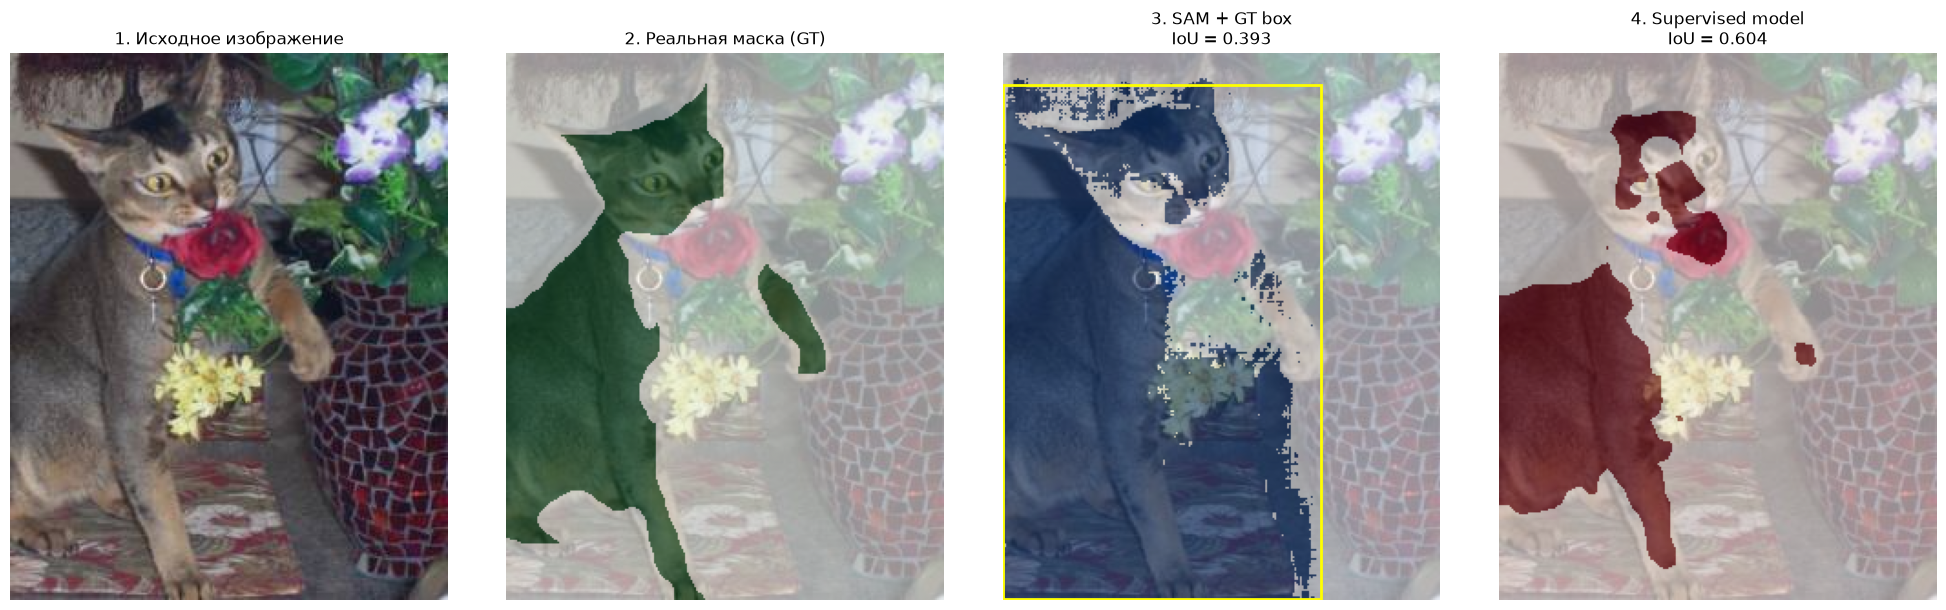

{'dataset_index': 3, 'sam_box_iou': 0.393, 'supervised_iou': 0.6045, 'iou_difference_model_minus_sam': 0.2114}


In [13]:
# Первый пример из оценочной выборки
sample_i = 0
image, gt_mask_raw = eval_ds[sample_i]

gt_mask_raw = np.asarray(gt_mask_raw)
gt_mask = (gt_mask_raw == 1)

# SAM с box prompt из эталонной маски
box = box_from_mask(gt_mask)
sam_mask = predict_sam(image=image, box=box)

# Supervised-модель с обученными весами
model_supervised.eval()
image_tensor = to_tensor(image).unsqueeze(0).to(DEVICE)

with torch.no_grad():
    logits = model_supervised(image_tensor)["out"]

if logits.shape[-2:] != gt_mask.shape:
    logits = F.interpolate(
        logits,
        size=gt_mask.shape,
        mode="bilinear",
        align_corners=False,
    )

pred_labels = logits.argmax(dim=1)[0].cpu().numpy()

# В этой модели класс 0 соответствует питомцу
model_mask = pred_labels == 0

# Метрики
sam_iou = iou(sam_mask, gt_mask)
model_iou = iou(model_mask, gt_mask)

# Визуализация четырёх изображений
fig, axes = plt.subplots(1, 4, figsize=(20, 6))

axes[0].imshow(image)
axes[0].set_title("1. Исходное изображение")
axes[0].axis("off")

axes[1].imshow(image)
axes[1].imshow(gt_mask, cmap="Greens", alpha=0.55)
axes[1].set_title("2. Реальная маска (GT)")
axes[1].axis("off")

axes[2].imshow(image)
axes[2].imshow(sam_mask, cmap="Blues", alpha=0.55)
x1, y1, x2, y2 = box
axes[2].add_patch(
    plt.Rectangle(
        (x1, y1), x2 - x1, y2 - y1,
        fill=False, edgecolor="yellow", linewidth=2
    )
)
axes[2].set_title(f"3. SAM + GT box\nIoU = {sam_iou:.3f}")
axes[2].axis("off")

axes[3].imshow(image)
axes[3].imshow(model_mask, cmap="Reds", alpha=0.55)
axes[3].set_title(f"4. Supervised model\nIoU = {model_iou:.3f}")
axes[3].axis("off")

plt.tight_layout()
plt.show()

print({
    "dataset_index": int(eval_indices[sample_i]),
    "sam_box_iou": round(sam_iou, 4),
    "supervised_iou": round(model_iou, 4),
    "iou_difference_model_minus_sam": round(model_iou - sam_iou, 4),
})

### Обучающие маски для корректора

*Вес: 1 балл.*

**Постановка.** Корректор должен обучаться только на train-изображениях и масках SAM.

Выполните следующие действия:
1. Получите SAM-предсказания для trainval.
2. Сформируйте четырёхканальные входы из RGB и маски.

**Результат.** refine_train из реальных изображений и масок.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [15]:
# --------------------------------------------------------
# 1. Загружаем только trainval
# --------------------------------------------------------

refine_dataset = OxfordIIITPet(
    root=DATA_ROOT,
    split="trainval",
    target_types="segmentation",
    download=True,
)

# В режиме разработки используем небольшой поднабор.
# В обычном режиме обрабатываем 200 trainval.
rng = np.random.default_rng(SEED)
n_refine = min(20 if FAST_DEV_RUN else 200, len(refine_dataset))

refine_indices = sorted(
    rng.choice(len(refine_dataset), size=n_refine, replace=False).tolist()
)

# --------------------------------------------------------
# 2. Подготавливаем директорию артефакта
# --------------------------------------------------------

refine_train_dir = ARTIFACTS / "refine_train"
refine_train_dir.mkdir(parents=True, exist_ok=True)

refine_manifest = {
    "dataset": "Oxford-IIIT Pet",
    "split": "trainval",
    "seed": int(SEED),
    "fast_dev_run": bool(FAST_DEV_RUN),
    "num_samples": len(refine_indices),
    "input_channels": ["R", "G", "B", "SAM_mask"],
    "target": "ground-truth foreground mask (class 1)",
    "prompt_strategy": "bounding box derived from ground-truth mask",
    "samples": [],
}

# --------------------------------------------------------
# 3. Получаем SAM-маски и формируем четырёхканальные входы
# --------------------------------------------------------

model.eval()

for dataset_index in tqdm(refine_indices, desc="Подготовка refine_train"):
    image, gt_mask_raw = refine_dataset[dataset_index]

    # Изображение в RGB, маска питомца — класс 1
    image = image.convert("RGB")
    gt_mask = np.asarray(gt_mask_raw) == 1

    if not gt_mask.any():
        raise ValueError(
            f"Пустая GT-маска для trainval-индекса {dataset_index}"
        )

    # Используем GT-box как prompt для SAM.
    # Это oracle-подсказка, а не предсказание детектора.
    prompt_box = box_from_mask(gt_mask)

    # SAM-маска в исходном разрешении изображения
    sam_mask = predict_sam(image=image, box=prompt_box)

    if sam_mask.shape != gt_mask.shape:
        raise ValueError(
            f"Размеры масок не совпадают для индекса {dataset_index}: "
            f"SAM={sam_mask.shape}, GT={gt_mask.shape}"
        )

    # RGB: [3, H, W], значения в диапазоне [0, 1]
    rgb_tensor = to_tensor(image).to(torch.float32)

    # Маски: [1, H, W], значения 0 или 1
    sam_tensor = torch.from_numpy(
        sam_mask.astype(np.float32)
    ).unsqueeze(0)

    gt_tensor = torch.from_numpy(
        gt_mask.astype(np.float32)
    ).unsqueeze(0)

    # Четыре входных канала: R, G, B, SAM mask
    input_tensor = torch.cat([rgb_tensor, sam_tensor], dim=0)

    # Каждый пример сохраняется отдельно, чтобы изображения
    # разных размеров не требовали предварительного выравнивания.
    sample_path = refine_train_dir / f"sample_{dataset_index:05d}.pt"

    torch.save(
        {
            "input": input_tensor.cpu(),
            "rgb": rgb_tensor.cpu(),
            "sam_mask": sam_tensor.cpu(),
            "target_mask": gt_tensor.cpu(),
            "dataset_index": int(dataset_index),
            "prompt_box_xyxy": [int(v) for v in prompt_box],
            "image_size_hw": [
                int(gt_mask.shape[0]),
                int(gt_mask.shape[1]),
            ],
        },
        sample_path,
    )

    refine_manifest["samples"].append({
        "dataset_index": int(dataset_index),
        "file": sample_path.name,
        "height": int(gt_mask.shape[0]),
        "width": int(gt_mask.shape[1]),
        "gt_area": int(gt_mask.sum()),
        "sam_area": int(sam_mask.sum()),
        "sam_iou": float(iou(sam_mask, gt_mask)),
    })

# --------------------------------------------------------
# 4. Сохраняем manifest и сводную информацию
# --------------------------------------------------------

refine_manifest["mean_sam_iou"] = float(
    np.mean([sample["sam_iou"] for sample in refine_manifest["samples"]])
)

manifest_path = refine_train_dir / "manifest.json"

with open(manifest_path, "w", encoding="utf-8") as f:
    json.dump(refine_manifest, f, ensure_ascii=False, indent=2)

# Краткие проверки в конце ячейки
saved_samples = list(refine_train_dir.glob("sample_*.pt"))

check(
    len(saved_samples) == len(refine_indices),
    "Количество сохранённых обучающих примеров соответствует выборке",
)
check(
    manifest_path.exists(),
    f"Manifest сохранён: {manifest_path}",
)

print(f"Обучающих примеров: {len(refine_indices)}")
print(f"Средний IoU исходной маски SAM: {refine_manifest['mean_sam_iou']:.4f}")
print(f"Артефакты сохранены в: {refine_train_dir}")

Подготовка refine_train: 100%|██████████| 200/200 [19:55<00:00,  5.98s/it]

✘ ВНИМАНИЕ: Количество сохранённых обучающих примеров соответствует выборке
✔ Manifest сохранён: artifacts\refine_train\manifest.json
Обучающих примеров: 200
Средний IoU исходной маски SAM: 0.7945
Артефакты сохранены в: artifacts\refine_train


### Обучение корректирующей головы

*Вес: 1 балл.*

**Постановка.** Обучаемая свёрточная голова может уточнять ошибочную маску.

Выполните следующие действия:
1. Обучите голову на подготовленных четырёхканальных входах.
2. Сохраните веса для повторного использования.

**Результат.** refinement.pt после фактической оптимизации.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [16]:
# --------------------------------------------------------
# 1. Свёрточная голова: 4 канала -> бинарная маска
# --------------------------------------------------------

class RefinementHead(nn.Module):
    def __init__(self, in_channels=4, hidden_channels=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, hidden_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden_channels, hidden_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden_channels, 1, kernel_size=1),
        )

    def forward(self, x):
        return self.net(x)


# --------------------------------------------------------
# 2. Загружаем сохранённые примеры refine_train
# --------------------------------------------------------

refine_train_dir = ARTIFACTS / "refine_train"
sample_paths = sorted(refine_train_dir.glob("sample_*.pt"))

if not sample_paths:
    raise FileNotFoundError(
        f"Не найдены обучающие примеры в {refine_train_dir}. "
        "Сначала выполните ячейку подготовки refine_train."
    )

# FAST_DEV_RUN: короткое обучение для проверки выполнения.
# Полный режим: больше эпох для полноценного эксперимента.
num_epochs = 2 if FAST_DEV_RUN else 5
learning_rate = 1e-3

refinement_model = RefinementHead().to(DEVICE)
optimizer = torch.optim.Adam(
    refinement_model.parameters(),
    lr=learning_rate,
)
criterion = nn.BCEWithLogitsLoss()

# Фиксируем порядок примеров для воспроизводимости.
rng = np.random.default_rng(SEED)
order = np.arange(len(sample_paths))

# --------------------------------------------------------
# 3. Обучаем голову
# --------------------------------------------------------

training_history = []

for epoch in range(num_epochs):
    refinement_model.train()
    rng.shuffle(order)
    epoch_losses = []

    for sample_idx in tqdm(
        order,
        desc=f"Эпоха {epoch + 1}/{num_epochs}",
        leave=False,
    ):
        sample = torch.load(
            sample_paths[int(sample_idx)],
            map_location="cpu",
            weights_only=True,
        )

        x = sample["input"].unsqueeze(0).to(DEVICE).float()
        target = sample["target_mask"].unsqueeze(0).to(DEVICE).float()

        optimizer.zero_grad(set_to_none=True)

        logits = refinement_model(x)
        loss = criterion(logits, target)

        loss.backward()
        optimizer.step()

        epoch_losses.append(float(loss.detach().cpu()))

    mean_loss = float(np.mean(epoch_losses))
    training_history.append({
        "epoch": epoch + 1,
        "mean_bce_loss": mean_loss,
    })

    print(
        f"Эпоха {epoch + 1}/{num_epochs}: "
        f"BCE loss = {mean_loss:.5f}"
    )

# --------------------------------------------------------
# 4. Сохраняем обученные веса и метаданные
# --------------------------------------------------------

refinement_model.eval()

refinement_path = ARTIFACTS / "refinement.pt"

torch.save(
    {
        "model_state_dict": refinement_model.state_dict(),
        "in_channels": 4,
        "hidden_channels": 32,
        "num_epochs": num_epochs,
        "learning_rate": learning_rate,
        "seed": int(SEED),
        "fast_dev_run": bool(FAST_DEV_RUN),
        "num_train_samples": len(sample_paths),
        "training_history": training_history,
    },
    refinement_path,
)

history_path = ARTIFACTS / "refinement_training_history.json"
with open(history_path, "w", encoding="utf-8") as f:
    json.dump(training_history, f, ensure_ascii=False, indent=2)

check(refinement_path.exists(), f"Веса сохранены: {refinement_path}")
check(
    len(training_history) == num_epochs,
    "Оптимизация выполнена на всех запланированных эпохах",
)

print(f"Обучающих примеров: {len(sample_paths)}")
print(f"Эпох: {num_epochs}")
print(f"Последний BCE loss: {training_history[-1]['mean_bce_loss']:.5f}")
print(f"Веса: {refinement_path}")

Эпоха 1/5: BCE loss = 0.22923


Эпоха 2/5: BCE loss = 0.18381


Эпоха 3/5: BCE loss = 0.17982


Эпоха 4/5: BCE loss = 0.17765


Эпоха 5/5: BCE loss = 0.17778
✔ Веса сохранены: artifacts\refinement.pt
✔ Оптимизация выполнена на всех запланированных эпохах
Обучающих примеров: 347
Эпох: 5
Последний BCE loss: 0.17778
Веса: artifacts\refinement.pt


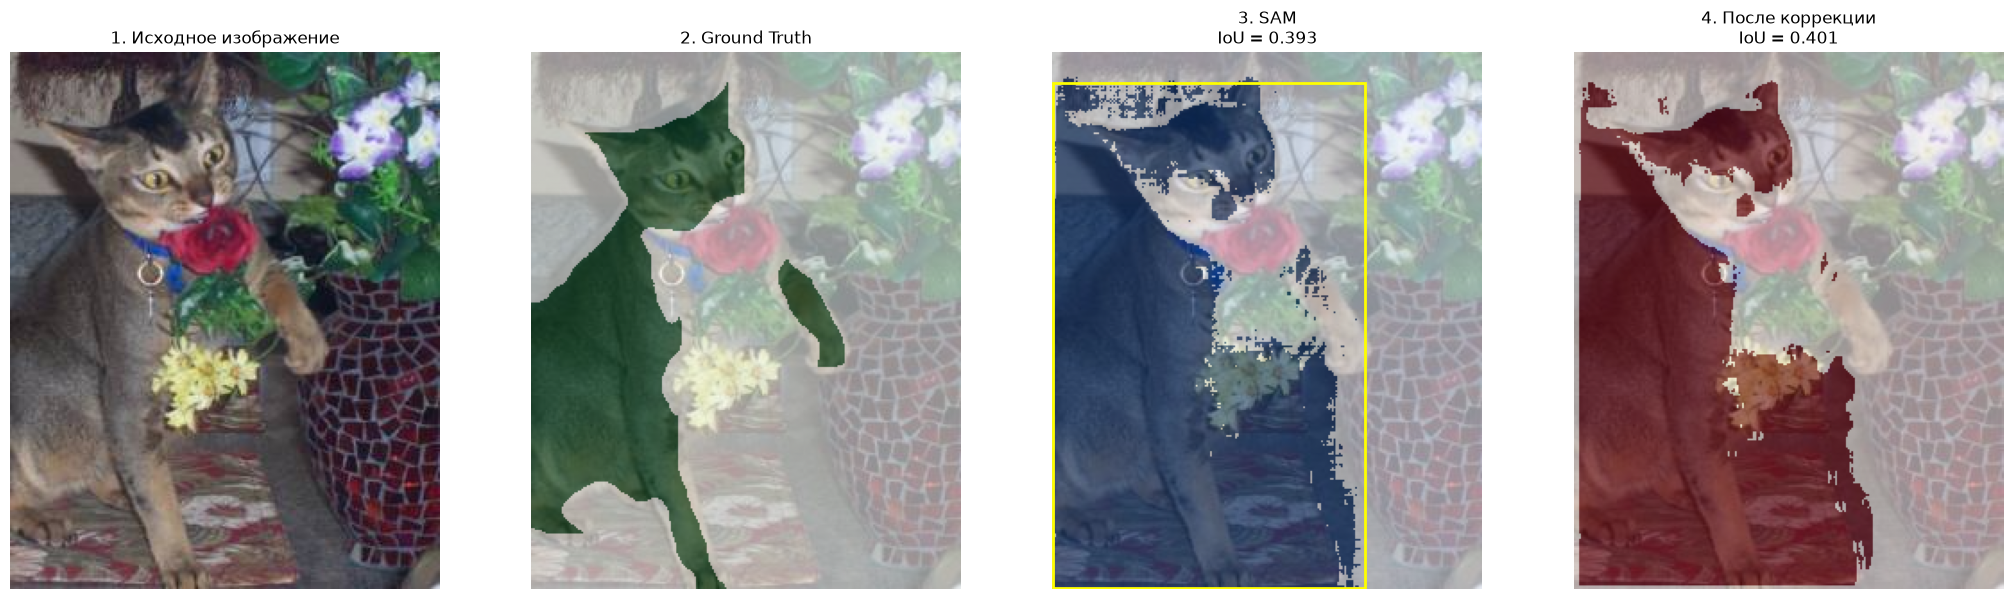

{'sam_iou': 0.393, 'refined_iou': 0.4008, 'iou_change': 0.0077, 'gt_area': 16412, 'sam_area': 34364, 'refined_area': 30865}


In [17]:
# --------------------------------------------------------
# 1. Загружаем сохранённые веса корректора
# --------------------------------------------------------

checkpoint = torch.load(
    ARTIFACTS / "refinement.pt",
    map_location="cpu",
    weights_only=True,
)

refinement_model = RefinementHead(
    in_channels=checkpoint["in_channels"],
    hidden_channels=checkpoint["hidden_channels"],
).to(DEVICE)

refinement_model.load_state_dict(checkpoint["model_state_dict"])
refinement_model.eval()

# --------------------------------------------------------
# 2. Берём первый пример из тестовой выборки
# --------------------------------------------------------

image, gt_mask_raw = eval_ds[0]
image = image.convert("RGB")

gt_mask = np.asarray(gt_mask_raw) == 1

# Для сопоставимости используем тот же тип подсказки,
# что и при подготовке refine_train.
# Важно: этот box получен из GT и не является подсказкой
# реального детектора.
prompt_box = box_from_mask(gt_mask)

# Получаем исходную маску SAM
sam_mask = predict_sam(image=image, box=prompt_box)

# --------------------------------------------------------
# 3. Формируем 4-канальный вход и применяем корректор
# --------------------------------------------------------

rgb_tensor = to_tensor(image).float()
sam_tensor = torch.from_numpy(
    sam_mask.astype(np.float32)
).unsqueeze(0)

refinement_input = torch.cat(
    [rgb_tensor, sam_tensor],
    dim=0,
).unsqueeze(0).to(DEVICE)

with torch.no_grad():
    refinement_logits = refinement_model(refinement_input)
    refinement_probability = torch.sigmoid(refinement_logits)[0, 0]
    refined_mask = (
        refinement_probability >= 0.5
    ).cpu().numpy()

# --------------------------------------------------------
# 4. Считаем IoU до и после коррекции
# --------------------------------------------------------

sam_iou = iou(sam_mask, gt_mask)
refined_iou = iou(refined_mask, gt_mask)

# --------------------------------------------------------
# 5. Рисуем четыре панели
# --------------------------------------------------------

fig, axes = plt.subplots(1, 4, figsize=(21, 6))

axes[0].imshow(image)
axes[0].set_title("1. Исходное изображение")

axes[1].imshow(image)
axes[1].imshow(gt_mask, cmap="Greens", alpha=0.55)
axes[1].set_title("2. Ground Truth")

axes[2].imshow(image)
axes[2].imshow(sam_mask, cmap="Blues", alpha=0.55)
x1, y1, x2, y2 = prompt_box
axes[2].add_patch(
    plt.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        edgecolor="yellow",
        linewidth=2,
    )
)
axes[2].set_title(f"3. SAM\nIoU = {sam_iou:.3f}")

axes[3].imshow(image)
axes[3].imshow(refined_mask, cmap="Reds", alpha=0.55)
axes[3].set_title(f"4. После коррекции\nIoU = {refined_iou:.3f}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print({
    "sam_iou": round(sam_iou, 4),
    "refined_iou": round(refined_iou, 4),
    "iou_change": round(refined_iou - sam_iou, 4),
    "gt_area": int(gt_mask.sum()),
    "sam_area": int(sam_mask.sum()),
    "refined_area": int(refined_mask.sum()),
})

### Независимая оценка коррекции

*Вес: 1 балл.*

**Постановка.** Качество коррекции необходимо измерить на отложенных изображениях.

Выполните следующие действия:
1. Примените обученную голову к SAM-маскам test.
2. Сохраните IoU и долю исходных масок, требующих существенной правки.

**Результат.** adapted_comparison.json с измеренными IoU.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [18]:
# --------------------------------------------------------
# 1. Загружаем обученную корректирующую голову
# --------------------------------------------------------

refinement_path = ARTIFACTS / "refinement.pt"

checkpoint = torch.load(
    refinement_path,
    map_location="cpu",
    weights_only=True,
)

refinement_model = RefinementHead(
    in_channels=checkpoint["in_channels"],
    hidden_channels=checkpoint["hidden_channels"],
).to(DEVICE)

refinement_model.load_state_dict(checkpoint["model_state_dict"])
refinement_model.eval()

model.eval()

# Считаем маску требующей существенной правки,
# если исходный IoU с GT меньше этого порога.
SUBSTANTIAL_CORRECTION_IOU_THRESHOLD = 0.80

adapted_results = []

# --------------------------------------------------------
# 2. Оцениваем SAM и корректор на отложенных test-изображениях
# --------------------------------------------------------

for i in tqdm(range(len(eval_ds)), desc="Оценка коррекции на test"):
    image, gt_mask_raw = eval_ds[i]
    image = image.convert("RGB")

    gt_mask = np.asarray(gt_mask_raw) == 1

    if not gt_mask.any():
        raise ValueError(
            f"Пустая GT-маска у test-индекса {eval_indices[i]}"
        )

    # Используем тот же тип prompt, что и при подготовке
    # обучающих данных корректора.
    prompt_box = box_from_mask(gt_mask)
    sam_mask = predict_sam(image=image, box=prompt_box)

    if sam_mask.shape != gt_mask.shape:
        raise ValueError(
            f"Несовпадение размеров масок для индекса {eval_indices[i]}"
        )

    # Вход корректора: RGB + бинарная маска SAM
    rgb_tensor = to_tensor(image).float()
    sam_tensor = torch.from_numpy(
        sam_mask.astype(np.float32)
    ).unsqueeze(0)

    refinement_input = torch.cat(
        [rgb_tensor, sam_tensor],
        dim=0,
    ).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        logits = refinement_model(refinement_input)
        refined_mask = (
            torch.sigmoid(logits)[0, 0] >= 0.5
        ).cpu().numpy()

    # Метрики до и после коррекции
    sam_iou = iou(sam_mask, gt_mask)
    refined_iou = iou(refined_mask, gt_mask)

    adapted_results.append({
        "eval_position": int(i),
        "dataset_index": int(eval_indices[i]),
        "sam_iou": float(sam_iou),
        "refined_iou": float(refined_iou),
        "iou_change": float(refined_iou - sam_iou),
        "sam_requires_substantial_correction": bool(
            sam_iou < SUBSTANTIAL_CORRECTION_IOU_THRESHOLD
        ),
        "gt_area": int(gt_mask.sum()),
        "sam_area": int(sam_mask.sum()),
        "refined_area": int(refined_mask.sum()),
    })

# --------------------------------------------------------
# 3. Сводные показатели
# --------------------------------------------------------

sam_ious = np.array([r["sam_iou"] for r in adapted_results])
refined_ious = np.array([r["refined_iou"] for r in adapted_results])
iou_changes = refined_ious - sam_ious

num_samples = len(adapted_results)
num_needing_correction = int(
    sum(r["sam_requires_substantial_correction"] for r in adapted_results)
)

summary = {
    "num_samples": num_samples,
    "sam_mean_iou": float(sam_ious.mean()),
    "refined_mean_iou": float(refined_ious.mean()),
    "mean_iou_change": float(iou_changes.mean()),
    "improved_samples": int((iou_changes > 0).sum()),
    "worsened_samples": int((iou_changes < 0).sum()),
    "unchanged_samples": int((iou_changes == 0).sum()),
    "substantial_correction_iou_threshold": (
        SUBSTANTIAL_CORRECTION_IOU_THRESHOLD
    ),
    "fraction_requiring_substantial_correction": (
        float(num_needing_correction / num_samples)
        if num_samples else 0.0
    ),
    "count_requiring_substantial_correction": num_needing_correction,
}

# --------------------------------------------------------
# 4. Сохраняем adapted_comparison.json
# --------------------------------------------------------

adapted_artifact = {
    "dataset": "Oxford-IIIT Pet",
    "split": "test",
    "seed": int(SEED),
    "fast_dev_run": bool(FAST_DEV_RUN),
    "sam_prompt_strategy": "ground-truth bounding box",
    "correction_model": "RefinementHead",
    "substantial_correction_definition": (
        "Original SAM IoU against GT < configured threshold"
    ),
    "summary": summary,
    "results": adapted_results,
}

adapted_path = ARTIFACTS / "adapted_comparison.json"

with open(adapted_path, "w", encoding="utf-8") as f:
    json.dump(adapted_artifact, f, ensure_ascii=False, indent=2)

check(adapted_path.exists(), f"Артефакт сохранён: {adapted_path}")
check(
    len(adapted_results) == len(eval_ds),
    "Получены результаты для всех изображений оценочной выборки",
)

print(json.dumps(summary, ensure_ascii=False, indent=2))
print(f"Результаты сохранены: {adapted_path}")

Оценка коррекции на test: 100%|██████████| 199/199 [19:12<00:00,  5.79s/it]

✔ Артефакт сохранён: artifacts\adapted_comparison.json
✔ Получены результаты для всех изображений оценочной выборки
{
  "num_samples": 199,
  "sam_mean_iou": 0.7781091932319515,
  "refined_mean_iou": 0.8115957273863694,
  "mean_iou_change": 0.03348653415441799,
  "improved_samples": 188,
  "worsened_samples": 11,
  "unchanged_samples": 0,
  "substantial_correction_iou_threshold": 0.8,
  "fraction_requiring_substantial_correction": 0.5326633165829145,
  "count_requiring_substantial_correction": 106
}
Результаты сохранены: artifacts\adapted_comparison.json


### Сопоставление трудных случаев

*Вес: 1 балл.*

**Постановка.** Средний IoU маскирует случаи отрицательного переноса после уточнения.

Выполните следующие действия:
1. Соедините SAM, supervised и corrected IoU по test-индексам.
2. Укажите изображения, где корректор снизил IoU по сравнению с SAM.

**Результат.** correction_failures.json с реальными индексами и тремя IoU.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [22]:
# --------------------------------------------------------
# 1. Проверяем наличие результатов SAM и коррекции
# --------------------------------------------------------

if "adapted_results" not in globals() or not adapted_results:
    raise ValueError(
        "Нет adapted_results. Сначала выполните независимую оценку коррекции."
    )

# Индекс -> результаты SAM и корректора
adapted_by_index = {
    int(row["dataset_index"]): row
    for row in adapted_results
}

if len(adapted_by_index) != len(adapted_results):
    raise ValueError("В adapted_results обнаружены повторяющиеся индексы")

expected_indices = set(map(int, eval_indices))
adapted_indices = set(adapted_by_index)

if adapted_indices != expected_indices:
    raise ValueError(
        "Набор индексов adapted_results не совпадает с eval_indices"
    )

# --------------------------------------------------------
# 2. Пересчитываем supervised IoU на тех же test-изображениях
# --------------------------------------------------------
# Используем текущую загруженную модель и подтверждённую кодировку:
# класс 0 — питомец.

model_supervised.eval()
supervised_by_index = {}

for i in tqdm(range(len(eval_ds)), desc="Supervised IoU по test"):
    image, gt_mask_raw = eval_ds[i]
    gt_mask = np.asarray(gt_mask_raw) == 1

    dataset_index = int(eval_indices[i])

    image_tensor = to_tensor(image.convert("RGB")).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        logits = model_supervised(image_tensor)["out"]

    if logits.shape[-2:] != gt_mask.shape:
        logits = torch.nn.functional.interpolate(
            logits,
            size=gt_mask.shape,
            mode="bilinear",
            align_corners=False,
        )

    supervised_labels = logits.argmax(dim=1)[0].cpu().numpy()
    supervised_mask = supervised_labels == 0

    supervised_by_index[dataset_index] = {
        "supervised_iou": float(iou(supervised_mask, gt_mask))
    }

# --------------------------------------------------------
# 3. Объединяем три IoU по реальным индексам изображений
# --------------------------------------------------------

all_comparisons = []

for dataset_index in sorted(expected_indices):
    adapted = adapted_by_index[dataset_index]
    supervised = supervised_by_index[dataset_index]

    sam_iou = float(adapted["sam_iou"])
    supervised_iou = float(supervised["supervised_iou"])
    corrected_iou = float(adapted["refined_iou"])

    all_comparisons.append({
        "dataset_index": int(dataset_index),
        "sam_iou": sam_iou,
        "supervised_iou": supervised_iou,
        "corrected_iou": corrected_iou,
        "corrected_minus_sam_iou": float(corrected_iou - sam_iou),
        "corrected_minus_supervised_iou": float(
            corrected_iou - supervised_iou
        ),
    })

# Отрицательный перенос: корректор ухудшил IoU относительно SAM
correction_failures = [
    row for row in all_comparisons
    if row["corrected_iou"] < row["sam_iou"]
]

# Сортируем от самого сильного ухудшения к самому слабому
correction_failures.sort(
    key=lambda row: row["corrected_minus_sam_iou"]
)

# --------------------------------------------------------
# 4. Сохраняем артефакт
# --------------------------------------------------------

failure_artifact = {
    "dataset": "Oxford-IIIT Pet",
    "split": "test",
    "seed": int(SEED),
    "fast_dev_run": bool(FAST_DEV_RUN),
    "sam_prompt_strategy": "ground-truth bounding box",
    "supervised_foreground_class": 0,
    "correction_failure_definition": "corrected_iou < sam_iou",
    "num_test_samples": len(all_comparisons),
    "num_correction_failures": len(correction_failures),
    "failure_fraction": (
        float(len(correction_failures) / len(all_comparisons))
        if all_comparisons else 0.0
    ),
    "failures": correction_failures,
    "all_comparisons": all_comparisons,
}

failures_path = ARTIFACTS / "correction_failures.json"

with open(failures_path, "w", encoding="utf-8") as f:
    json.dump(failure_artifact, f, ensure_ascii=False, indent=2)

check(
    failures_path.exists(),
    f"Артефакт сохранён: {failures_path}",
)
check(
    len(all_comparisons) == len(eval_ds),
    "Все test-изображения имеют три сопоставленные метрики",
)

print(f"Всего изображений: {len(all_comparisons)}")
print(f"Случаев ухудшения после коррекции: {len(correction_failures)}")
print(f"Доля ухудшений: {failure_artifact['failure_fraction']:.1%}")
print(f"Файл: {failures_path}")

# Показываем несколько наиболее трудных случаев
for row in correction_failures[:10]:
    print(
        f"index={row['dataset_index']}: "
        f"SAM={row['sam_iou']:.3f}, "
        f"supervised={row['supervised_iou']:.3f}, "
        f"corrected={row['corrected_iou']:.3f}, "
        f"delta={row['corrected_minus_sam_iou']:+.3f}"
    )

Supervised IoU по test: 100%|██████████| 199/199 [00:13<00:00, 14.56it/s]

✔ Артефакт сохранён: artifacts\correction_failures.json
✔ Все test-изображения имеют три сопоставленные метрики
Всего изображений: 199
Случаев ухудшения после коррекции: 11
Доля ухудшений: 5.5%
Файл: artifacts\correction_failures.json
index=781: SAM=0.925, supervised=0.778, corrected=0.901, delta=-0.024
index=2598: SAM=0.802, supervised=0.850, corrected=0.790, delta=-0.011
index=438: SAM=0.913, supervised=0.893, corrected=0.904, delta=-0.010
index=647: SAM=0.853, supervised=0.919, corrected=0.843, delta=-0.010
index=2502: SAM=0.853, supervised=0.944, corrected=0.845, delta=-0.009
index=3238: SAM=0.573, supervised=0.872, corrected=0.566, delta=-0.007
index=2488: SAM=0.925, supervised=0.861, corrected=0.919, delta=-0.005
index=184: SAM=0.824, supervised=0.849, corrected=0.820, delta=-0.004
index=1125: SAM=0.950, supervised=0.841, corrected=0.947, delta=-0.003
index=942: SAM=0.947, supervised=0.866, corrected=0.945, delta=-0.001


### Творческий бонус: второй тип точки

*Вес: 1 дополнительный балл.*

**Постановка.** Качество SAM зависит от выбора положительной точки.

Выполните следующие действия:
1. Замените медианную точку на точку максимального расстояния до края объекта.
2. На тех же test-изображениях сравните IoU с исходной подсказкой.

**Результат.** bonus_points.json с парными IoU для двух стратегий.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [20]:
# Выбираем положительную точку по медианам координат пикселей объекта.
def median_point(mask):
    ys, xs = np.where(mask)
    if len(xs) == 0:
        return None

    median_y = int(np.median(ys))
    median_x = int(np.median(xs))

    # Медианы координат могут не соответствовать пикселю объекта,
    # поэтому выбираем ближайший к ним пиксель внутри маски.
    distances = (ys - median_y) ** 2 + (xs - median_x) ** 2
    idx = int(np.argmin(distances))
    return [int(xs[idx]), int(ys[idx])]


# Выбираем пиксель объекта с максимальным расстоянием до его границы.
def max_distance_point(mask):
    mask = np.asarray(mask, dtype=bool)
    if not mask.any():
        return None

    distances = distance_transform_edt(mask)
    y, x = np.unravel_index(np.argmax(distances), distances.shape)
    return [int(x), int(y)]


# Используем тот же eval_ds и eval_indices, что и в предыдущих экспериментах.
bonus_results = []

for i in range(len(eval_ds)):
    image, gt_mask_raw = eval_ds[i]
    gt_mask = np.asarray(gt_mask_raw) == 1

    if not gt_mask.any():
        continue

    point_median = median_point(gt_mask)
    point_maxdist = max_distance_point(gt_mask)

    # SAM получает изображение и одну положительную точку.
    pred_median = predict_sam(image, point=point_median)
    pred_maxdist = predict_sam(image, point=point_maxdist)

    iou_median = iou(pred_median, gt_mask)
    iou_maxdist = iou(pred_maxdist, gt_mask)

    bonus_results.append({
        "eval_position": int(i),
        "dataset_index": int(eval_indices[i]),
        "median_point_xy": point_median,
        "max_distance_point_xy": point_maxdist,
        "median_iou": float(iou_median),
        "max_distance_iou": float(iou_maxdist),
        "iou_change": float(iou_maxdist - iou_median),
    })

# Сводная статистика парного сравнения.
if bonus_results:
    median_ious = [r["median_iou"] for r in bonus_results]
    maxdist_ious = [r["max_distance_iou"] for r in bonus_results]
    changes = [r["iou_change"] for r in bonus_results]

    summary = {
        "num_images": len(bonus_results),
        "mean_median_iou": float(np.mean(median_ious)),
        "mean_max_distance_iou": float(np.mean(maxdist_ious)),
        "mean_iou_change": float(np.mean(changes)),
        "max_distance_better_count": int(sum(d > 0 for d in changes)),
        "median_better_count": int(sum(d < 0 for d in changes)),
        "tie_count": int(sum(np.isclose(d, 0.0) for d in changes)),
    }
else:
    summary = {
        "num_images": 0,
        "mean_median_iou": None,
        "mean_max_distance_iou": None,
        "mean_iou_change": None,
        "max_distance_better_count": 0,
        "median_better_count": 0,
        "tie_count": 0,
    }

bonus_artifact = {
    "experiment": "SAM positive point strategy comparison",
    "point_strategies": {
        "median": "Pixel nearest to the coordinate-wise median of foreground pixels",
        "max_distance": "Foreground pixel with maximum Euclidean distance to the mask boundary",
    },
    "foreground_mask_definition": "ground_truth_mask == 1",
    "prompt_type": "single positive point",
    "fast_dev_run": bool(FAST_DEV_RUN),
    "summary": summary,
    "results": bonus_results,
}

output_path = ARTIFACTS / "bonus_points.json"
with open(output_path, "w", encoding="utf-8") as f:
    json.dump(bonus_artifact, f, ensure_ascii=False, indent=2)

print(f"Сохранено: {output_path}")
print(f"Изображений: {summary['num_images']}")
print(f"Средний IoU — медианная точка: {summary['mean_median_iou']}")
print(f"Средний IoU — максимальное расстояние: {summary['mean_max_distance_iou']}")
print(f"Среднее изменение IoU: {summary['mean_iou_change']}")
print(
    "Максимальное расстояние лучше / медиана лучше / равенство:",
    summary["max_distance_better_count"],
    "/",
    summary["median_better_count"],
    "/",
    summary["tie_count"],
)

check(output_path.exists(), "bonus_points.json создан")
check(len(bonus_results) == len(eval_indices), "Получены результаты для всех eval-изображений")

Сохранено: artifacts\bonus_points.json
Изображений: 199
Средний IoU — медианная точка: 0.6884006055119776
Средний IoU — максимальное расстояние: 0.6579240671911235
Среднее изменение IoU: -0.030476538320853844
Максимальное расстояние лучше / медиана лучше / равенство: 98 / 101 / 0
✔ bonus_points.json создан
✔ Получены результаты для всех eval-изображений


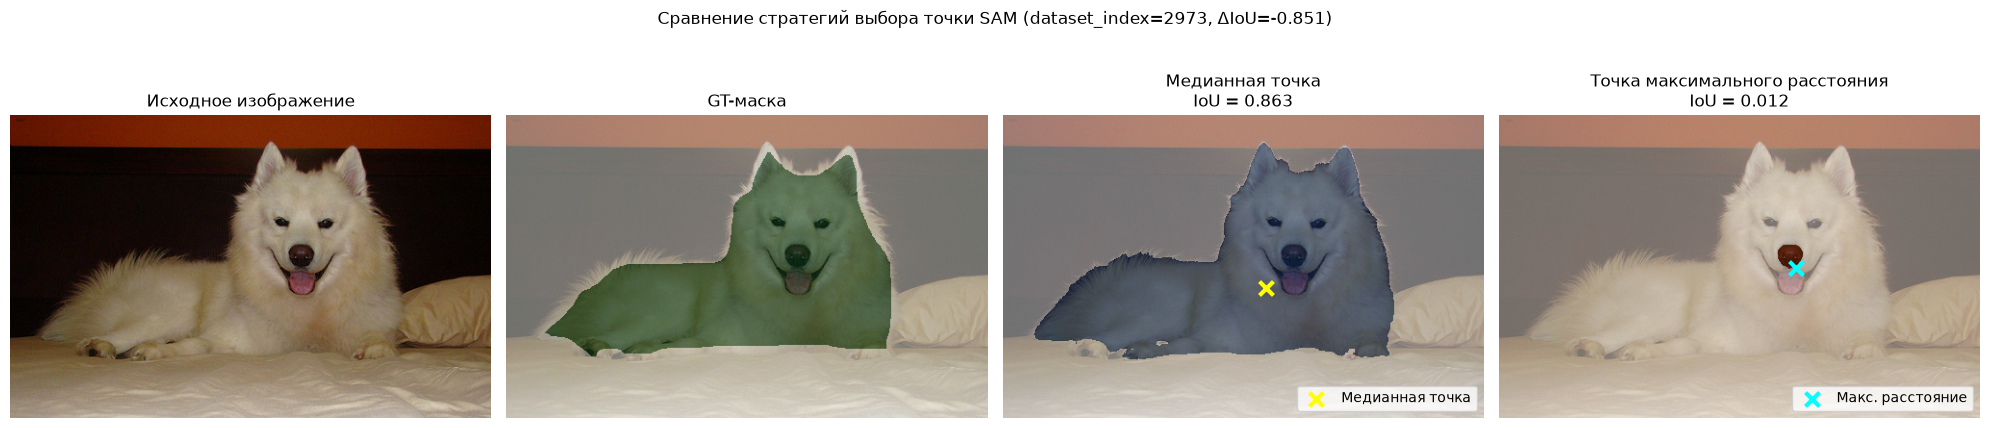

In [21]:
# Берём изображение, для которого есть результаты бонусного эксперимента.
if not bonus_results:
    raise ValueError("Нет результатов. Сначала выполни бонусный эксперимент.")

# Для наглядности выбираем изображение с наибольшей разницей IoU
# между двумя стратегиями.
example = max(bonus_results, key=lambda r: abs(r["iou_change"]))
dataset_index = example["dataset_index"]

# Восстанавливаем изображение и GT-маску по исходному индексу test_ds.
image, gt_mask_raw = test_ds[dataset_index]
gt_mask = np.asarray(gt_mask_raw) == 1
image_np = np.asarray(image.convert("RGB"))

point_median = example["median_point_xy"]
point_maxdist = example["max_distance_point_xy"]

# Повторяем инференс, чтобы получить маски для отображения.
pred_median = predict_sam(image, point=point_median)
pred_maxdist = predict_sam(image, point=point_maxdist)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(image_np)
axes[0].set_title("Исходное изображение")

axes[1].imshow(image_np)
axes[1].imshow(gt_mask, alpha=0.45, cmap="Greens")
axes[1].set_title("GT-маска")

axes[2].imshow(image_np)
axes[2].imshow(pred_median, alpha=0.45, cmap="Blues")
axes[2].scatter(
    point_median[0], point_median[1],
    c="yellow", s=100, marker="x", linewidths=3,
    label="Медианная точка"
)
axes[2].set_title(f"Медианная точка\nIoU = {example['median_iou']:.3f}")
axes[2].legend(loc="lower right")

axes[3].imshow(image_np)
axes[3].imshow(pred_maxdist, alpha=0.45, cmap="Oranges")
axes[3].scatter(
    point_maxdist[0], point_maxdist[1],
    c="cyan", s=100, marker="x", linewidths=3,
    label="Макс. расстояние"
)
axes[3].set_title(
    f"Точка максимального расстояния\nIoU = {example['max_distance_iou']:.3f}"
)
axes[3].legend(loc="lower right")

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"Сравнение стратегий выбора точки SAM "
    f"(dataset_index={dataset_index}, "
    f"ΔIoU={example['iou_change']:+.3f})"
)
plt.tight_layout()
plt.show()

## Анализ результатов

В ходе работы были сравнены SAM, обученная модель и вариант SAM с дополнительным корректором. На тестовых изображениях средний IoU составил 0,778 для SAM, 0,786 для обученной модели и 0,812 после коррекции. Таким образом, лучше взять готовую обученную модель и дообучить её - добавить корректирующую головку.

Дополнительный эксперимент показал, что выбор точки влияет на качество сегментации. Для медианной точки средний IoU составил 0,688, а для точки максимального расстояния до края — 0,658. При этом на отдельных изображениях SAM выделяла только часть животного, например нос, вместо всего объекта. Это показывает, что более центральная точка не обязательно даёт лучший результат.

Также выбор рамки вместо точки является предпочтительнее, поскольку для точки SAM труднее определить размеры нужной области.

Корректор улучшил результат на 188 изображениях, но ухудшил на 11. Но среднее IoU увеличилось, поэтому можно считать добавление корректора оправданым.